# 第099讲 CPU可复现实验
先读lecture.md与lab.md。本笔记本实际运行相同脚本、测试并显示图像；输出不是手工粘贴。

In [1]:
import sys, pathlib, subprocess, json
print(sys.version)
print('Experiment file present:', pathlib.Path('experiment.py').is_file())

3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]
Experiment file present: True


In [2]:
result=subprocess.run([sys.executable,'experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout)
print('Script exit:',result.returncode)

{
  "checks": {
    "framework_output_error": 3.885780586188048e-16,
    "manual_gradient_errors_QKV": [
      1.1102230246251565e-16,
      1.1102230246251565e-16,
      0.0
    ],
    "finite_difference_q_error": 9.777333456750803e-11,
    "future_perturbation_masked_error": 0.0,
    "future_perturbation_unmasked_change": 20.062713624227136,
    "padding_append_error": 0.0,
    "blocked_weight_max": 0.0,
    "row_sum_error": 2.220446049250313e-16
  },
  "hand_example": {
    "scores": [
      [
        0.7071067811865475,
        0.0,
        0.7071067811865475
      ],
      [
        0.0,
        0.7071067811865475,
        0.7071067811865475
      ],
      [
        0.7071067811865475,
        0.7071067811865475,
        1.414213562373095
      ]
    ],
    "unmasked_weights": [
      [
        0.4011120926797859,
        0.1977758146404282,
        0.4011120926797859
      ],
      [
        0.1977758146404282,
        0.4011120926797859,
        0.4011120926797859
      ],
     

In [3]:
result=subprocess.run([sys.executable,'-m','unittest','-v','test_experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout+'\n'.join(line for line in result.stderr.splitlines() if line.strip() != 'Fontconfig error: No writable cache directories'))

test_all_blocked_rejected (test_experiment.Tests.test_all_blocked_rejected) ... ok
test_causal_future (test_experiment.Tests.test_causal_future) ... ok
test_cross_attention_shape (test_experiment.Tests.test_cross_attention_shape) ... ok
test_finite_difference (test_experiment.Tests.test_finite_difference) ... ok
test_manual_gradients (test_experiment.Tests.test_manual_gradients) ... ok
test_padding (test_experiment.Tests.test_padding) ... ok
test_probability (test_experiment.Tests.test_probability) ... ok
test_reference (test_experiment.Tests.test_reference) ... ok
test_unmasked_counterexample (test_experiment.Tests.test_unmasked_counterexample) ... ok

----------------------------------------------------------------------
Ran 9 tests in 0.009s

OK


In [4]:
data=json.loads(pathlib.Path('outputs/results.json').read_text())
print('Result fields:', list(data))

Result fields: ['checks', 'hand_example', 'configuration', 'complexity']


01_weights.png
02_mechanism.png


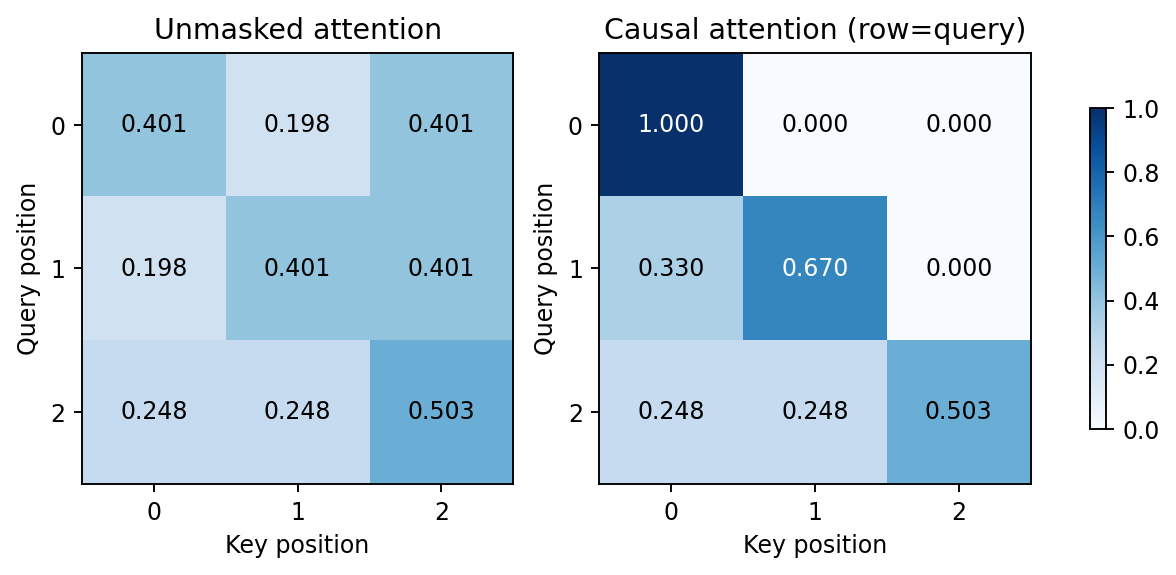

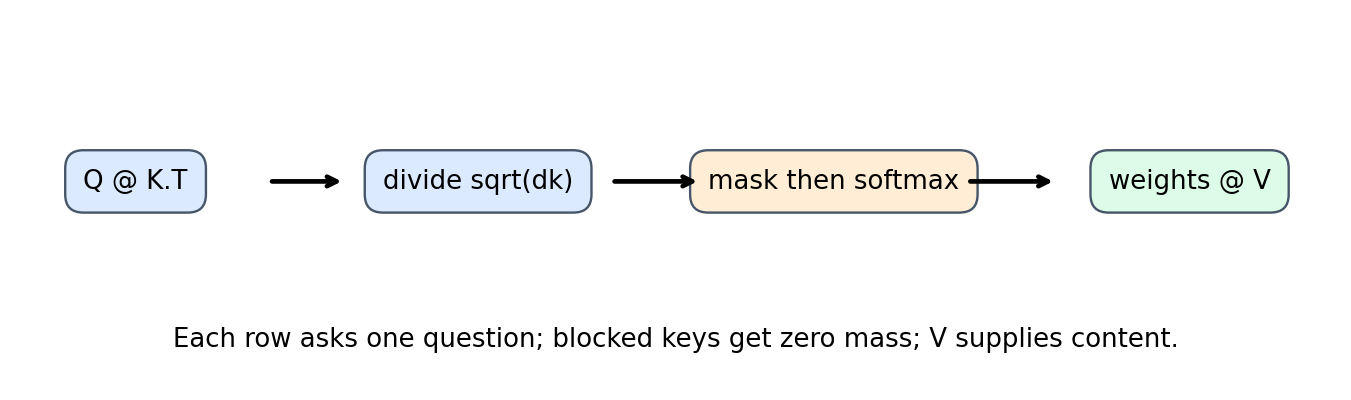

In [5]:
from IPython.display import display, Image
for p in sorted(pathlib.Path('figures').glob('*.png')):
    print(p.name)
    display(Image(filename=str(p)))

解释任务：逐项说明图中的控制变量、预算口径、失败对照和不能支持的结论。详细答案见answers.md。